In [2]:
import numpy as np
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import torch
%matplotlib inline

In [3]:
sns.set(style='white', context='notebook', rc={'figure.figsize':(14,10)})

In [4]:
EMBEDDING_PATH = "/data/hqvo3/codes/LaBo/datasets/CUB/embs/concepttrans_eva_img_embs_512_aug0_iters1_test.pth"
LABEL_PATH = "/data/hqvo3/codes/LaBo/datasets/CUB/embs/concepttrans_eva_labels_512_aug0_iters1_test.pth"

In [5]:
test_embs = torch.load(EMBEDDING_PATH)
test_labels = torch.load(LABEL_PATH)

In [6]:
print(len(test_embs))
print(len(test_labels))

5794
5794


In [7]:
print(test_embs[0].shape)
print(test_labels[0])

torch.Size([1, 768])
18


In [8]:
test_embs[0, 0, 0]

tensor(0.0201)

In [55]:
n_emb_dims = test_embs[0, 0].shape[0]
n_uniq_labels = len(list(set(test_labels)))
print('-> n_uniq_labels: ', n_uniq_labels)

-> n_uniq_labels:  200


In [25]:
combined_embs = []
index_list = []
column_list = []
# flag = False

tmp_cnt = 0
for sample_idx, test_emb in enumerate(test_embs):
    
    row_combined_embs = []
    tmp_cnt += 1
    # iterate over different dimensions of embedding
    emb_dim_cnt = 0
    for emb_idx, emb_ele in enumerate(test_emb[0]):
        emb_dim_cnt += 1
        row_combined_embs.append(emb_ele.item())
        if sample_idx == 0:
            print(emb_idx)
            column_list.append(f'dim {str(emb_idx)}')
        # if flag == False:
        #     print('[*] emb_ele: ', emb_ele.item())
        #     flag = True
    row_combined_embs.append(test_labels[sample_idx])
    if sample_idx == 0:
        column_list.append('label')

    combined_embs.append(row_combined_embs)
    index_list.append(sample_idx)

print('-> tmp_cnt: ', tmp_cnt)

0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
101
102
103
104
105
106
107
108
109
110
111
112
113
114
115
116
117
118
119
120
121
122
123
124
125
126
127
128
129
130
131
132
133
134
135
136
137
138
139
140
141
142
143
144
145
146
147
148
149
150
151
152
153
154
155
156
157
158
159
160
161
162
163
164
165
166
167
168
169
170
171
172
173
174
175
176
177
178
179
180
181
182
183
184
185
186
187
188
189
190
191
192
193
194
195
196
197
198
199
200
201
202
203
204
205
206
207
208
209
210
211
212
213
214
215
216
217
218
219
220
221
222
223
224
225
226
227
228
229
230
231
232
233
234
235
236
237
238
239
240
241
242
243
244
245
246
247
248
249
250
251
252
253
254
255
256
257
258
259
260
261
262
263
264
265
266
267
268
269
270
271
272
273
274
275
276
27

In [27]:
# index_list
# column_list
# index_list.append('All Classes')
combined_embs_dataframe = pd.DataFrame(combined_embs, index=index_list, columns=column_list)
combined_embs_dataframe

,dim 0,dim 1,dim 2,dim 3,dim 4,dim 5,dim 6,dim 7,dim 8,dim 9,...,dim 759,dim 760,dim 761,dim 762,dim 763,dim 764,dim 765,dim 766,dim 767,label
0,0.020131,0.017499,0.004192,-0.019780,0.021166,-0.016183,0.006228,0.008671,0.001009,0.019697,...,-0.013654,-0.013428,0.006734,-0.003785,-0.022222,0.017031,0.020120,0.038747,-0.003176,18
1,0.025349,0.014122,0.010129,-0.010897,0.025231,-0.014480,0.013263,0.000170,0.003924,0.015149,...,-0.010279,-0.008194,-0.003082,-0.016449,-0.015179,0.009074,0.010471,0.043722,-0.003335,18
2,0.021783,0.009075,-0.003951,-0.013507,0.021119,-0.020155,0.003302,0.000276,0.009445,0.020572,...,-0.006266,-0.006581,0.010802,-0.011843,-0.023784,0.010283,0.019898,0.036690,0.005732,18
3,0.026663,0.000750,0.007645,-0.023518,0.024297,-0.013729,0.002964,-0.008478,0.015055,0.037398,...,-0.011041,-0.021360,0.001204,-0.004076,-0.010819,0.012284,0.012610,0.036693,0.006275,18
4,0.024665,0.009241,0.007760,-0.014406,0.025666,-0.015226,0.003448,0.000252,0.011384,0.016436,...,-0.014054,-0.001019,0.008109,-0.008113,-0.027540,0.015443,0.021762,0.040905,0.005011,18
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5789,0.013215,0.027301,0.001899,0.000060,-0.002752,-0.039060,0.011015,0.011015,0.013603,0.031434,...,0.006310,-0.006100,0.003790,0.008261,-0.027718,0.010109,-0.000410,0.045548,-0.000807,54
5790,0.013997,0.012593,0.007447,0.002190,0.001356,-0.033944,0.013229,0.011833,0.016817,0.025321,...,0.006363,-0.013176,-0.010725,-0.004695,-0.023278,0.013531,0.000758,0.041837,-0.001722,54
5791,0.013135,0.006134,-0.001579,0.002480,0.005611,-0.027721,0.004488,0.005943,0.020455,0.033067,...,0.000381,-0.005743,-0.004619,-0.001293,-0.020875,0.014550,0.001941,0.039381,0.001880,54
5792,0.013662,0.020453,-0.006088,0.001005,0.003201,-0.027503,0.010619,0.009441,0.019764,0.029399,...,-0.003082,-0.005629,-0.004587,-0.000542,-0.022418,0.012128,0.003205,0.044102,0.002483,54


In [29]:
combined_embs_dataframe.head()

,dim 0,dim 1,dim 2,dim 3,dim 4,dim 5,dim 6,dim 7,dim 8,dim 9,...,dim 759,dim 760,dim 761,dim 762,dim 763,dim 764,dim 765,dim 766,dim 767,label
0,0.020131,0.017499,0.004192,-0.019780,0.021166,-0.016183,0.006228,0.008671,0.001009,0.019697,...,-0.013654,-0.013428,0.006734,-0.003785,-0.022222,0.017031,0.020120,0.038747,-0.003176,18
1,0.025349,0.014122,0.010129,-0.010897,0.025231,-0.014480,0.013263,0.000170,0.003924,0.015149,...,-0.010279,-0.008194,-0.003082,-0.016449,-0.015179,0.009074,0.010471,0.043722,-0.003335,18
2,0.021783,0.009075,-0.003951,-0.013507,0.021119,-0.020155,0.003302,0.000276,0.009445,0.020572,...,-0.006266,-0.006581,0.010802,-0.011843,-0.023784,0.010283,0.019898,0.036690,0.005732,18
3,0.026663,0.000750,0.007645,-0.023518,0.024297,-0.013729,0.002964,-0.008478,0.015055,0.037398,...,-0.011041,-0.021360,0.001204,-0.004076,-0.010819,0.012284,0.012610,0.036693,0.006275,18
4,0.024665,0.009241,0.007760,-0.014406,0.025666,-0.015226,0.003448,0.000252,0.011384,0.016436,...,-0.014054,-0.001019,0.008109,-0.008113,-0.027540,0.015443,0.021762,0.040905,0.005011,18


In [39]:
import umap
reducer = umap.UMAP()

/data/hqvo3/miniconda3/envs/labo/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [37]:
embs_data = combined_embs_dataframe[
    [f'dim {i}' for i in range(n_emb_dims)]
].values
scaled_embs_data = StandardScaler().fit_transform(embs_data)

In [40]:
embedding = reducer.fit_transform(scaled_embs_data)
embedding.shape

(5794, 2)

In [52]:
combined_embs_dataframe.label

0       18
1       18
2       18
3       18
4       18
        ..
5789    54
5790    54
5791    54
5792    54
5793    54
Name: label, Length: 5794, dtype: int64

In [56]:
map_dict = {}
n_uniq_labels
for uniq_label in range(n_uniq_labels):
    map_dict[uniq_label] = uniq_label

combined_embs_dataframe.label.map(map_dict)
# type(combined_embs_dataframe.label)

0       18
1       18
2       18
3       18
4       18
        ..
5789    54
5790    54
5791    54
5792    54
5793    54
Name: label, Length: 5794, dtype: int64

In [63]:
sns.color_palette(n_colors=200)[10]

(0.2980392156862745, 0.4470588235294118, 0.6901960784313725)

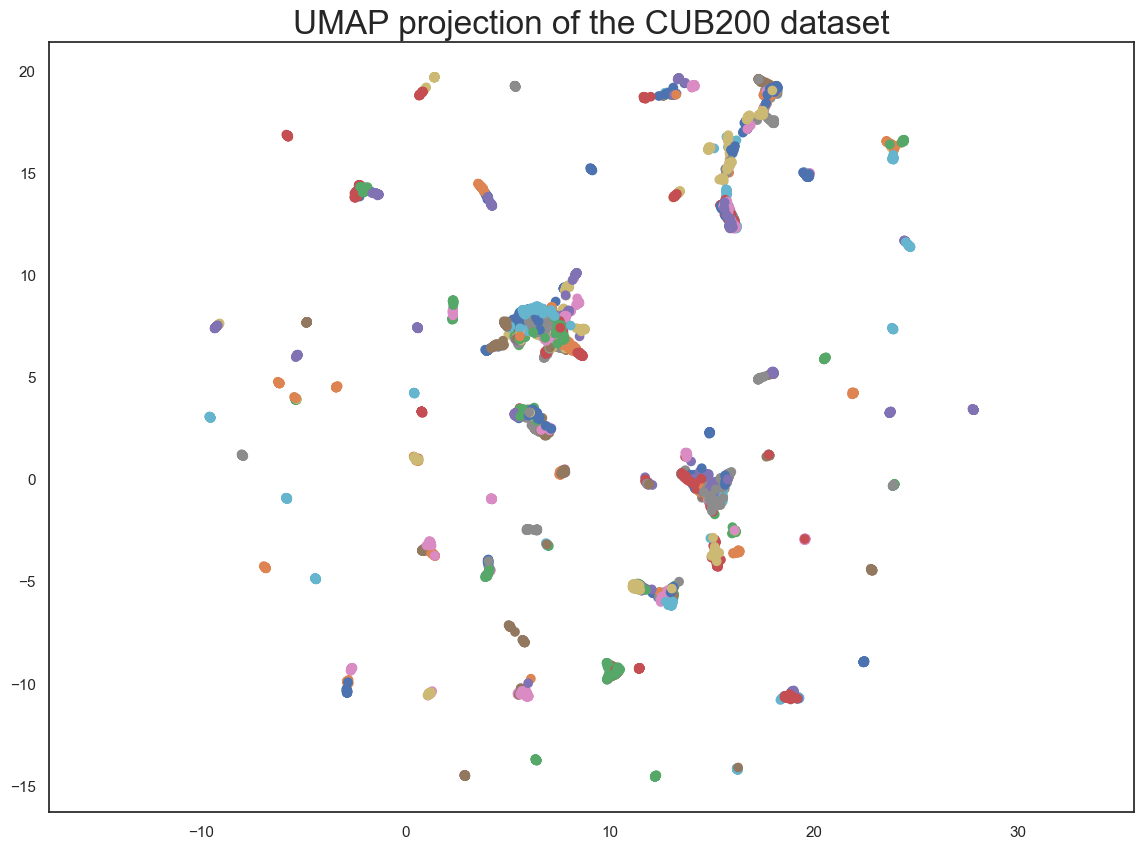

In [65]:
plt.scatter(
    embedding[:, 0],
    embedding[:, 1],
    c=[sns.color_palette(n_colors=200)[x] for x in combined_embs_dataframe.label.map(map_dict)])
plt.gca().set_aspect('equal', 'datalim')
plt.title('UMAP projection of the CUB200 dataset', fontsize=24);